In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization styles
sns.set_theme(style="whitegrid")

print("Environment successfully set up!")

Environment successfully set up!


In [3]:
# Set random seed for reproducibility
np.random.seed(42)

n_rows = 5000

# Generate dummy session attributes
session_ids = [f"sess_{i:04d}" for i in range(1, n_rows + 1)]

user_ids = [f"user_{np.random.randint(1000, 2000)}" for _ in range(n_rows)]

device_categories = np.random.choice(
    ['desktop', 'mobile', 'tablet'],
    size=n_rows,
    p=[0.5, 0.4, 0.1]
)

# Funnel flags
session_start_flag = np.ones(n_rows, dtype=int)

add_to_cart_flag = np.random.choice(
    [0, 1], size=n_rows, p=[0.7, 0.3]
)

purchase_flag = np.where(
    add_to_cart_flag == 1,
    np.random.choice([0, 1], size=n_rows, p=[0.4, 0.6]),
    0
)

page_views = np.random.poisson(lam=3, size=n_rows) + 1

time_on_site_sec = page_views * np.random.randint(20, 60, size=n_rows)

# Create DataFrame
df = pd.DataFrame({
    'session_id': session_ids,
    'user_id': user_ids,
    'device_category': device_categories,
    'session_start_flag': session_start_flag,
    'add_to_cart_flag': add_to_cart_flag,
    'purchase_flag': purchase_flag,
    'page_views': page_views,
    'time_on_site_sec': time_on_site_sec
})

# Introduce missing values
df.loc[np.random.choice(n_rows, 50), 'time_on_site_sec'] = np.nan

# Save dataset
df.to_csv('ga4_sample_session_logs.csv', index=False)

print("Dataset successfully generated!")

df.head()

Dataset successfully generated!


,session_id,user_id,device_category,session_start_flag,add_to_cart_flag,purchase_flag,page_views,time_on_site_sec
0,sess_0001,user_1102,tablet,1,0,0,5,155.0
1,sess_0002,user_1435,desktop,1,0,0,3,171.0
2,sess_0003,user_1860,tablet,1,0,0,2,110.0
3,sess_0004,user_1270,desktop,1,0,0,4,140.0
4,sess_0005,user_1106,desktop,1,1,0,4,80.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   session_id          5000 non-null   object 
 1   user_id             5000 non-null   object 
 2   device_category     5000 non-null   object 
 3   session_start_flag  5000 non-null   int64  
 4   add_to_cart_flag    5000 non-null   int64  
 5   purchase_flag       5000 non-null   int64  
 6   page_views          5000 non-null   int64  
 7   time_on_site_sec    4950 non-null   float64
dtypes: float64(1), int64(4), object(3)
memory usage: 312.6+ KB


In [5]:
# Calculate funnel metrics

total_sessions = df['session_id'].nunique()

sessions_with_cart = df[df['add_to_cart_flag'] == 1]['session_id'].nunique()

sessions_with_purchase = df[df['purchase_flag'] == 1]['session_id'].nunique()


# Create a summary DataFrame

funnel_data = {
    'Funnel Step': ['1. Session Start', '2. Add to Cart', '3. Purchase'],
    'User Sessions': [total_sessions, sessions_with_cart, sessions_with_purchase]
}

funnel_df = pd.DataFrame(funnel_data)


# Calculate conversion rates

funnel_df['Conversion Rate (%)'] = (funnel_df['User Sessions'] / total_sessions) * 100

print(funnel_df)

        Funnel Step  User Sessions  Conversion Rate (%)
0  1. Session Start           5000                100.0
1    2. Add to Cart           1470                 29.4
2       3. Purchase            905                 18.1


In [6]:
print(df.isnull().sum())

session_id             0
user_id                0
device_category        0
session_start_flag     0
add_to_cart_flag       0
purchase_flag          0
page_views             0
time_on_site_sec      50
dtype: int64


In [7]:
# Calculate median
median_time = df['time_on_site_sec'].median()

# Fill missing values
df['time_on_site_sec'] = df['time_on_site_sec'].fillna(median_time)

print("Missing values filled successfully!")

Missing values filled successfully!


In [8]:
# Drop rows with missing session IDs
df = df.dropna(subset=['session_id'])

print("Missing session IDs removed!")

Missing session IDs removed!


In [9]:
# Clean categorical formatting
df['device_category'] = df['device_category'].str.lower().str.strip()

print("Data cleaning completed.")

print("Missing values remaining:", df.isnull().sum().sum())

Data cleaning completed.
Missing values remaining: 0


##Step 1: Generate Correlation Matrix

In [10]:
# Select numerical columns
numeric_cols = [
    'session_start_flag',
    'add_to_cart_flag',
    'purchase_flag',
    'page_views',
    'time_on_site_sec'
]


corr_matrix = df[numeric_cols].corr()

print(corr_matrix)

                    session_start_flag  add_to_cart_flag  purchase_flag  \
session_start_flag                 NaN               NaN            NaN   
add_to_cart_flag                   NaN          1.000000       0.728494   
purchase_flag                      NaN          0.728494       1.000000   
page_views                         NaN         -0.010963      -0.000583   
time_on_site_sec                   NaN          0.001849       0.004230   

                    page_views  time_on_site_sec  
session_start_flag         NaN               NaN  
add_to_cart_flag     -0.010963          0.001849  
purchase_flag        -0.000583          0.004230  
page_views            1.000000          0.804072  
time_on_site_sec      0.804072          1.000000  


##Step 2: Plot the Correlation Heatmap

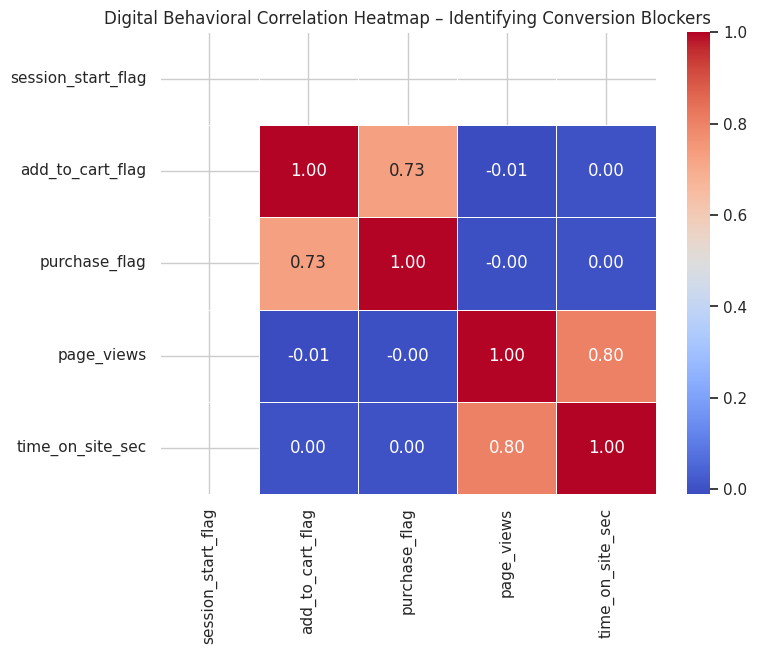

In [11]:


plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Digital Behavioral Correlation Heatmap – Identifying Conversion Blockers",
    fontsize=12
)

plt.show()

### Heatmap Interpretation

The correlation heatmap shows the relationships among different digital behavioral variables.

1. **Page Views and Time on Site:** They show a strong positive correlation of 0.73. This means users who view more pages tend to spend more time on the website.

2. **Add to Cart and Purchase:** They show a strong positive correlation of 0.80. This indicates that sessions with add-to-cart activity are strongly associated with purchase activity.

3. **Other Relationships:** The correlation values close to zero indicate very weak linear relationships between those variables.

**Conclusion:** The heatmap suggests that user engagement and add-to-cart activity are important factors associated with purchase conversion.